# Blackjack enhancement 3: OMC with count-based optimistic exploration

**IE 692 course project.** Same simplified Blackjack MDP as the baseline (cards 2-5 with
replacement, dealer draws to 9+, bust above 11, gamma = 0.9). Follows the GridWorld
enhancement 3 notebook, adapted to Blackjack's complete-episode Monte Carlo estimator.

| | Baseline (TOMC) | E3 control: OMC, $\beta=0$ | E3: OMC + bonus |
|---|---|---|---|
| Pairs that must reach $L(s,a)\ge100$ before an update | $\pi_k(a\mid s)\ge0.05$ | all 64 | all 64 |
| $\widehat Q$ of a rarely chosen action | fallback $1/(1-\gamma)=10$ | its sampled returns | its sampled returns |
| Score used in the KL update | $\widehat Q_k$ | $\widehat Q_k$ | $\widehat Q_k-b_k$ |

The bonus uses **cumulative** visit counts over the whole run (reset only for a new run):
$$b_k(s,a)=\beta\sqrt{\frac{2\ln(2+N_k(s))}{1+N_k(s,a)}},\qquad N_k(s)=\sum_a N_k(s,a),$$
$$\pi_{k+1}(a\mid s)\propto\pi_k(a\mid s)\exp\!\big[-\eta\big(\widehat Q_k(s,a)-b_k(s,a)\big)\big].$$
Costs are minimized, so the bonus is subtracted. $N_k$ includes the batch just collected.

What is run:
1. **Checks.** Baseline estimator, OMC coverage without fallback, zero-probability actions,
   bonus and update (copied from GridWorld), cumulative counts, reproduction of the baseline
   with the same code, RNG independence, exact model.
2. **Tuning.** eta in {0.1, 1, 10} x beta in {0, 0.1, 1, 10}, 10% of the budget each,
   tuning seed 100. For every beta, eta is tuned separately (its own row of the sweep).
   The baseline is tuned with its own rule and budget.
3. **Full runs.** The baseline and every beta at its tuned eta, `SAMPLE_BUDGET`
   observations each, seeds 0-4.
4. **Evaluation (never used for training).** Exact Bellman V^pi and 500 independent test games
   per evaluated policy (about 200 checkpoints at most), aligned by training observations.
5. **Plots.** The baseline and all betas together (value with training times, loss rate,
   policy updates) and a tuning summary.

**How to run:** `python blackjack_enhancement3.py` (or the `# %%` cells in VS Code / Jupyter).
Self-contained. Dependencies: NumPy, pandas, Matplotlib. Figures go to `figures/`,
results to `results/`.

In [1]:
# 1. Settings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

GAMMA = 0.9
MIN_SUFFIX_STEPS = 100                    # A batch ends once every required pair has L(s,a) >= 100.
SAMPLE_BUDGET = 4_000_000                   # Training observations per run (same for all methods).
TUNING_BUDGET = SAMPLE_BUDGET // 10       # 10% of the budget = 200,000 observations per configuration.
SEEDS = (0, 1, 2, 3, 4)                   # Five independent full runs.
TUNING_SEED = 100                         # Tuning uses its own seed, separate from the full runs.
TEST_GAMES = 500                          # Independent loss-rate evaluation games per policy.
N_CHECKPOINTS = 200                       # At most about 200 evaluated policies per run.

ETA_CANDIDATES = (0.1, 1.0, 10.0)         # Policy stepsize (all methods).
BETA_CANDIDATES = (0.0, 0.1, 1.0, 10.0)   # beta = 0 is the OMC-only control.
TIE_TOLERANCE = 1e-6                      # Gaps at (8, 4) closer than this count as tied.

CARD_VALUES = (2, 3, 4, 5)                # Infinite deck, drawn with replacement.
BUST_LIMIT = 11                           # A sum above 11 is a bust.
DEALER_STANDS_AT = 9                      # Dealer draws until the sum is 9 or more.
WIN, DRAW, LOSS = -1.0, 0.0, 1.0          # Costs to minimize.

PLAYER_SUMS = range(4, 12)                # 8 player sums (4..11)
DEALER_CARDS = range(2, 6)                # 4 dealer up-cards (2..5)
N_STATES, N_ACTIONS = 32, 2               # All 32 states kept; none excluded as unreachable.
STICK, HIT = 0, 1
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS    # 0.05: TOMC baseline ONLY; never used by OMC.
FALLBACK_Q = 1 / (1 - GAMMA)              # 10.0: TOMC baseline ONLY.
ALL_PAIRS = np.ones((N_STATES, N_ACTIONS), dtype=bool)   # OMC: every pair is required.


def state2ID(player_sum, dealer_card):
    """Map (player sum 4..11, dealer card 2..5) to a state index 0..31."""
    return (player_sum - 4) * 4 + (dealer_card - 2)


REF_PLAYER_SUM, REF_DEALER_CARD = 8, 4
REPORT_STATE = state2ID(REF_PLAYER_SUM, REF_DEALER_CARD)
REPORT_LABEL = f"({REF_PLAYER_SUM}, {REF_DEALER_CARD})"
UNIFORM_POLICY = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)

# Plot style shared with the other notebooks; method colors follow the GridWorld E3 figure.
BASELINE_COLOR = "#6f6e69"
OMC_COLOR = "#eb6834"                     # OMC, beta = 0 (GridWorld E3 control color).
BONUS_COLOR = "#2a78d6"                   # OMC + bonus (GridWorld E3 bonus color).
BETA_COLORS = dict(zip(BETA_CANDIDATES, (OMC_COLOR, "#2f9e6e", BONUS_COLOR, "#8a5cc2", "#c2a03a")))
INK = "#0b0b0b"
MUTED = "#52514e"
BACKGROUND = "#fcfcfb"
GRID_COLOR = "#e6e5e0"
FIGURES, RESULTS = Path("figures"), Path("results")

## 2. Environment (copied unchanged from the baseline)

In [2]:
class RandomStream:
    """Buffered cards and uniforms from one seeded NumPy generator."""

    def __init__(self, rng, block=1 << 16):
        self.rng, self.block = rng, block
        self._cards, self._uniforms = [], []

    def card(self):
        if not self._cards:
            self._cards = self.rng.choice(CARD_VALUES, size=self.block).tolist()
        return self._cards.pop()

    def uniform(self):
        if not self._uniforms:
            self._uniforms = self.rng.random(self.block).tolist()
        return self._uniforms.pop()


def stick_cost(player_sum, dealer_card, stream):
    """Dealer draws to DEALER_STANDS_AT or more; return the player's terminal cost."""
    dealer_sum = dealer_card
    while dealer_sum < DEALER_STANDS_AT:
        dealer_sum += stream.card()
    if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
        return WIN
    return LOSS if player_sum < dealer_sum else DRAW


def play_hand(hit_prob, stream):
    """One complete hand. hit_prob[s] = pi(HIT | s). Returns (states, actions, costs)."""
    player_sum = stream.card() + stream.card()
    dealer_card = stream.card()
    states, actions, costs = [], [], []
    while True:
        state = state2ID(player_sum, dealer_card)
        states.append(state)
        if stream.uniform() < hit_prob[state]:
            actions.append(HIT)
            player_sum += stream.card()
            if player_sum > BUST_LIMIT:
                costs.append(LOSS)
                return states, actions, costs
            costs.append(0.0)
        else:
            actions.append(STICK)
            costs.append(stick_cost(player_sum, dealer_card, stream))
            return states, actions, costs

## 3. Episodic batches: TOMC (baseline) and OMC (enhancement 3)

The baseline's collector and estimator are unchanged. The only addition is an optional
`required` argument: by default it is the baseline's TOMC set $\pi_k(a\mid s)\ge0.05$, so the
baseline behaves exactly as before; OMC passes `ALL_PAIRS`. With every pair required, every
$\widehat Q$ entry is an average of real complete returns and the fallback never applies.
A batch that runs out of budget is incomplete: its observations are counted, but it gives
no update. There is no probability floor: an action with probability 0 is never sampled,
so an OMC batch that requires it can only end by exhausting the budget.

In [3]:
def empty_batch():
    pairs = N_STATES * N_ACTIONS
    return {"return_sum": [0.0] * pairs, "return_count": [0] * pairs, "suffix_steps": [0] * pairs}


def add_hand(batch, states, actions, costs, gamma, eligible, min_steps):
    """Add every complete return of one hand; return how many eligible pairs just reached min_steps."""
    hand_length, G, newly_complete = len(costs), 0.0, 0
    for t in range(hand_length - 1, -1, -1):
        G = costs[t] + gamma * G
        pair = states[t] * N_ACTIONS + actions[t]
        before = batch["suffix_steps"][pair]
        batch["suffix_steps"][pair] += hand_length - t
        batch["return_sum"][pair] += G
        batch["return_count"][pair] += 1
        if eligible[pair] and before < min_steps <= batch["suffix_steps"][pair]:
            newly_complete += 1
    return newly_complete


def collect_batch(policy, stream, gamma=GAMMA, min_steps=MIN_SUFFIX_STEPS,
                  observations_left=np.inf, required=None):
    """Play hands under the frozen policy until all required pairs have L >= min_steps.

    required=None is the baseline's TOMC rule (pi >= 0.05); OMC passes ALL_PAIRS.
    """
    eligible_mask = policy >= PI_THRESHOLD if required is None else np.asarray(required, dtype=bool)
    eligible = eligible_mask.ravel().tolist()
    hit_prob = policy[:, HIT].tolist()
    batch, missing, observations, hands = empty_batch(), int(eligible_mask.sum()), 0, 0

    while missing > 0 and observations < observations_left:
        states, actions, costs = play_hand(hit_prob, stream)
        missing -= add_hand(batch, states, actions, costs, gamma, eligible, min_steps)
        observations += len(costs)
        hands += 1

    counts = np.array(batch["return_count"]).reshape(policy.shape)
    steps = np.array(batch["suffix_steps"]).reshape(policy.shape)
    sums = np.array(batch["return_sum"]).reshape(policy.shape)
    q_hat = np.full(policy.shape, FALLBACK_Q)
    q_hat[eligible_mask] = sums[eligible_mask] / np.maximum(counts[eligible_mask], 1)
    return {"q_hat": q_hat, "complete": missing == 0, "observations": observations,
            "hands": hands, "return_count": counts, "suffix_steps": steps,
            "eligible": eligible_mask}


def kl_spmd_update(policy, q_hat, eta):
    scores = -eta * q_hat
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


def run_spmd(max_observations, eta, seed, verbose=False):
    """Baseline: KL-SPMD + episodic TOMC until the training observation budget is used."""
    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    stream = RandomStream(np.random.default_rng(train_seed))
    policy = UNIFORM_POLICY.copy()
    policies, samples, records = [policy.copy()], [0], []
    used = 0
    started = time.perf_counter()

    while used < max_observations:
        batch = collect_batch(policy, stream, observations_left=max_observations - used)
        used += batch["observations"]
        if not batch["complete"]:
            break                                    # Budget ran out mid-batch: no update.
        records.append({
            "observations": batch["observations"],
            "cumulative_observations": used,
            "min_eligible_L": int(batch["suffix_steps"][batch["eligible"]].min()),
        })
        policy = kl_spmd_update(policy, batch["q_hat"], eta)
        policies.append(policy.copy())
        samples.append(used)

    seconds = time.perf_counter() - started
    if verbose:
        print(f"Baseline eta={eta:g}, seed={seed} | {len(records)} updates, {used:,} observations, "
              f"{seconds:.1f} s", flush=True)
    return {"seed": seed, "eta": eta, "policies": np.array(policies),
            "samples": np.array(samples), "history": pd.DataFrame(records, columns=[
                "observations", "cumulative_observations", "min_eligible_L"]),
            "total_observations": used, "seconds": seconds, "test_seed": test_seed}

## 4. Bonus, update and the E3 learning loop

`ucb_bonus` and `update_with_bonus` are the GridWorld E3 functions. The loop follows the same
order: collect a batch under the frozen policy, add **every** observed interaction to the
cumulative counts (also those of an incomplete final batch), and only for a complete batch
estimate $\widehat Q_k$, record $\widehat V_k(s_0)$ from the raw $\widehat Q_k$, and update with
the bonus from the cumulative counts. With $\beta=0$ the update is the baseline's KL-SPMD.

In [4]:
def validate_policy(policy):
    if not np.isfinite(policy).all() or (policy < 0).any():
        raise ValueError("policy probabilities must be finite and nonnegative")
    if not np.allclose(policy.sum(axis=1), 1.0, rtol=0, atol=1e-12):
        raise ValueError("each policy row must sum to one")


def ucb_bonus(cumulative_visits, beta):
    counts = np.asarray(cumulative_visits)
    if counts.ndim != 2 or not np.isfinite(counts).all() or (counts < 0).any():
        raise ValueError("counts must be a finite nonnegative 2D table")
    if not np.isfinite(beta) or beta < 0:
        raise ValueError("beta must be finite and nonnegative")
    if beta == 0:
        return np.zeros(counts.shape, dtype=float)
    state_visits = counts.sum(axis=1, keepdims=True)
    return beta * np.sqrt(2.0 * np.log(2.0 + state_visits) / (1.0 + counts))


def update_with_bonus(policy, q_hat, counts, beta, eta):
    # Sampled Q values stay intact; optimism enters only the update score.
    if not np.isfinite(eta) or eta < 0:
        raise ValueError("eta must be finite and nonnegative")
    if q_hat.shape != policy.shape or not np.isfinite(q_hat).all():
        raise ValueError("q_hat must be finite and match the policy")
    if counts.shape != policy.shape:
        raise ValueError("counts must match the policy")
    bonus = ucb_bonus(counts, beta)
    new_policy = kl_spmd_update(policy, q_hat - bonus, eta)
    if not np.isfinite(new_policy).all():
        raise FloatingPointError("Nonfinite policy; reduce beta or eta")
    validate_policy(new_policy)
    return new_policy, bonus


def run_e3(max_observations, eta, beta, seed, evaluation="omc", verbose=False):
    """One run with OMC coverage (or the TOMC rule, for reproducing the baseline) and the bonus."""
    if evaluation not in ("omc", "tomc"):
        raise ValueError("unknown evaluation method")
    if evaluation == "tomc" and beta != 0:
        raise ValueError("The TOMC reproduction never receives a bonus")
    ucb_bonus(np.zeros((1, 1), dtype=np.int64), beta)   # Validate beta before sampling.
    required = ALL_PAIRS if evaluation == "omc" else None

    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    stream = RandomStream(np.random.default_rng(train_seed))
    policy = UNIFORM_POLICY.copy()
    counts = np.zeros(policy.shape, dtype=np.int64)       # Cumulative visits N_k, fresh per run.
    policies, samples, records = [policy.copy()], [0], []
    q_tables, count_tables = [], []
    used = unfinished = 0
    started = time.perf_counter()

    while used < max_observations:
        batch = collect_batch(policy, stream, observations_left=max_observations - used,
                              required=required)
        used += batch["observations"]
        counts += batch["return_count"]                   # Every interaction is counted.
        assert batch["return_count"].sum() == batch["observations"] and counts.sum() == used
        if not batch["complete"]:
            unfinished = batch["observations"]            # Counted, but no partial update.
            break

        q_hat, req = batch["q_hat"], batch["eligible"]
        if evaluation == "omc":
            assert (batch["return_count"] > 0).all()      # Every Q entry is a real average.
        records.append({
            "observations": batch["observations"],
            "cumulative_observations": used,
            "min_eligible_L": int(batch["suffix_steps"][req].min()),
            "min_required_prob": float(policy[req].min()),
            "value_estimate": float(policy[REPORT_STATE] @ q_hat[REPORT_STATE]),   # Raw Q, no bonus.
        })
        q_tables.append(q_hat)
        count_tables.append(counts.copy())                # N_k used by this update.
        policy, bonus = update_with_bonus(policy, q_hat, counts, beta, eta)
        policies.append(policy.copy())
        samples.append(used)

    seconds = time.perf_counter() - started
    if verbose:
        print(f"E3 ({evaluation}) eta={eta:g}, beta={beta:g}, seed={seed} | {len(records)} updates, "
              f"{used:,} observations ({unfinished:,} in an unfinished batch), {seconds:.1f} s",
              flush=True)
    empty = np.zeros((0, N_STATES, N_ACTIONS))
    return {"seed": seed, "eta": float(eta), "beta": float(beta), "evaluation": evaluation,
            "policies": np.array(policies), "samples": np.array(samples),
            "history": pd.DataFrame(records, columns=[
                "observations", "cumulative_observations", "min_eligible_L", "min_required_prob",
                "value_estimate"]),
            "q_tables": np.array(q_tables) if q_tables else empty,
            "count_tables": np.array(count_tables) if count_tables else empty.astype(np.int64),
            "cumulative_visits": counts, "unfinished_observations": unfinished,
            "total_observations": used, "seconds": seconds, "test_seed": test_seed}

## 5. Exact model, used only for evaluation (copied unchanged from the baseline)

In [5]:
def dealer_final_distribution(dealer_card):
    """Exact probabilities of the dealer's final sum, starting from the up-card."""
    final, frontier = {}, {dealer_card: 1.0}
    while frontier:
        next_frontier = {}
        for total, prob in frontier.items():
            for card in CARD_VALUES:
                new_total, new_prob = total + card, prob / len(CARD_VALUES)
                target = final if new_total >= DEALER_STANDS_AT else next_frontier
                target[new_total] = target.get(new_total, 0.0) + new_prob
        frontier = next_frontier
    return final


def build_exact_model():
    """Return P[state, action, next_state] (substochastic) and c[state, action]."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.zeros((N_STATES, N_ACTIONS))
    for dealer_card in DEALER_CARDS:
        dealer = dealer_final_distribution(dealer_card)
        for player_sum in PLAYER_SUMS:
            s = state2ID(player_sum, dealer_card)
            for dealer_sum, prob in dealer.items():
                if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
                    c[s, STICK] += prob * WIN
                elif player_sum < dealer_sum:
                    c[s, STICK] += prob * LOSS
            for card in CARD_VALUES:
                prob = 1 / len(CARD_VALUES)
                if player_sum + card > BUST_LIMIT:
                    c[s, HIT] += prob * LOSS
                else:
                    P[s, HIT, state2ID(player_sum + card, dealer_card)] += prob
    return P, c


def exact_values(policy, P, c, gamma=GAMMA):
    """Exact V^pi for all 32 states (Bellman linear system)."""
    P_pi = np.einsum("sa,sat->st", policy, P)
    c_pi = np.sum(policy * c, axis=1)
    return np.linalg.solve(np.eye(N_STATES) - gamma * P_pi, c_pi)


def optimal_values(P, c, gamma=GAMMA, tol=1e-13):
    """Exact V* by value iteration (the player sum only increases, so it converges in a few sweeps)."""
    V = np.zeros(N_STATES)
    while True:
        V_new = np.min(c + gamma * P @ V, axis=1)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new
        V = V_new


P_exact, c_exact = build_exact_model()
V_STAR = optimal_values(P_exact, c_exact)
V_UNIFORM = exact_values(UNIFORM_POLICY, P_exact, c_exact)
OPTIMAL_ACTIONS = np.argmin(c_exact + GAMMA * P_exact @ V_STAR, axis=1)
print(f"Uniform policy: V{REPORT_LABEL} = {V_UNIFORM[REPORT_STATE]:.4f}")
print(f"Optimal policy: V*{REPORT_LABEL} = {V_STAR[REPORT_STATE]:.4f}")

Uniform policy: V(8, 4) = 0.5770
Optimal policy: V*(8, 4) = 0.2328


## 6. Independent evaluation, alignment, and storage

Policies are evaluated after training: exact $V^{\pi}$ and the loss rate in 500 test games
from the run's own test stream (never used for training). If a run has more than about
200 policies, log-spaced checkpoints (always including the first and last) are evaluated.
Curves carry each seed's latest evaluated policy forward without interpolation. The
completed-update count is exact at every observation count (all update times are kept).

In [6]:
def loss_rate(policy, stream, n_games=TEST_GAMES):
    """Fraction of independent test games that end in a loss (bust or lower than the dealer)."""
    hit_prob = policy[:, HIT].tolist()
    return np.mean([play_hand(hit_prob, stream)[2][-1] == LOSS for _ in range(n_games)])


def checkpoint_indices(n_policies, n_points=N_CHECKPOINTS):
    """All policy indices if there are at most n_points, else about n_points log-spaced ones."""
    if n_policies <= n_points:
        return np.arange(n_policies)
    spaced = np.round(np.geomspace(1, n_policies - 1, n_points)).astype(np.int64)
    return np.unique(np.concatenate([[0, n_policies - 1], spaced]))


def summarize_run(result):
    """Evaluate the checkpoint policies of one run (baseline or E3)."""
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    index = checkpoint_indices(len(result["policies"]))
    policies = result["policies"][index]
    summary = {
        "seed": result["seed"],
        "samples": result["samples"][index],
        "values": np.array([exact_values(pi, P_exact, c_exact) for pi in policies]),
        "loss_rate": np.array([loss_rate(pi, test_stream) for pi in policies]),
        "updates": index,
        "update_samples": result["samples"],          # Every update time, for the update curve.
        "observations": result["history"]["observations"].to_numpy(),
        "seconds": result["seconds"],
        "final_policy": result["policies"][-1],
    }
    if "count_tables" in result:                      # E3 only.
        summary.update({key: result[key] for key in (
            "q_tables", "count_tables", "cumulative_visits", "unfinished_observations")})
        summary["min_required_prob"] = result["history"]["min_required_prob"].to_numpy()
        summary["estimate"] = result["history"]["value_estimate"].to_numpy()
    return summary


T_975 = {2: 12.706, 3: 4.303, 4: 3.182, 5: 2.776, 6: 2.571, 7: 2.447, 8: 2.365, 9: 2.306, 10: 2.262}


def on_grid(run, points, metric):
    """Carry each seed's latest evaluated policy forward: the value of `metric` at each count."""
    index = np.searchsorted(run["samples"], points, side="right") - 1
    return np.asarray(run[metric])[index]


def updates_on_grid(run, points):
    """Exact number of completed policy updates at each observation count."""
    return np.searchsorted(run["update_samples"], points, side="right") - 1


def mean_ci(curves):
    """Mean and 95% half-width across seeds (rows)."""
    curves = np.asarray(curves, dtype=float)
    n = curves.shape[0]
    half_width = T_975[n] * curves.std(axis=0, ddof=1) / np.sqrt(n)
    return curves.mean(axis=0), half_width


def update_points(runs, budget, key="samples"):
    """Every observation count at which some seed changes, plus 0 and the budget."""
    points = np.unique(np.concatenate([[0, budget]] + [run[key] for run in runs]))
    return points[points <= budget]


def format_mean_ci(values, digits=4):
    mean, half_width = mean_ci(np.asarray(values, dtype=float)[:, None])
    return f"{mean[0]:.{digits}f} ± {half_width[0]:.{digits}f}"


BASELINE_KEYS = ("samples", "values", "loss_rate", "updates", "update_samples", "observations",
                 "final_policy")
E3_KEYS = BASELINE_KEYS + ("q_tables", "count_tables", "cumulative_visits",
                           "unfinished_observations", "min_required_prob", "estimate")


def save_runs(name, runs, keys, **settings):
    RESULTS.mkdir(exist_ok=True)
    arrays = {f"seed{run['seed']}_{key}": np.asarray(run[key]) for run in runs for key in keys}
    path = RESULTS / f"{name}.npz"
    np.savez(path, seeds=[run["seed"] for run in runs], seconds=[run["seconds"] for run in runs],
             **arrays, **settings)
    return path

## 7. Focused checks before running

In [7]:
def expect_error(call, error=ValueError):
    try:
        call()
    except error:
        return
    raise AssertionError(f"Expected {error.__name__}")


def check_episodic_estimator():
    """Baseline check: complete returns, separate N and L, fallback, budget stop."""
    gamma = 0.5
    eligible = [True] * (N_STATES * N_ACTIONS)
    batch = empty_batch()
    newly = add_hand(batch, [0, 5, 9], [HIT, HIT, STICK], [0.0, 0.0, 1.0], gamma, eligible, 3)
    assert newly == 1
    add_hand(batch, [0], [HIT], [1.0], gamma, eligible, 3)
    pair = 0 * N_ACTIONS + HIT
    assert batch["return_count"][pair] == 2 and batch["suffix_steps"][pair] == 3 + 1
    np.testing.assert_allclose(batch["return_sum"][pair], gamma**2 * 1.0 + 1.0)
    policy = UNIFORM_POLICY.copy()
    policy[REPORT_STATE] = [1 - PI_THRESHOLD / 2, PI_THRESHOLD / 2]
    result = collect_batch(policy, RandomStream(np.random.default_rng(7)))
    assert result["complete"] and result["q_hat"][REPORT_STATE, HIT] == FALLBACK_Q
    assert (result["suffix_steps"][result["eligible"]] >= MIN_SUFFIX_STEPS).all()
    short = collect_batch(UNIFORM_POLICY, RandomStream(np.random.default_rng(8)), observations_left=10)
    assert not short["complete"] and 10 <= short["observations"] <= 10 + N_STATES
    print("PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).")


def check_omc_without_fallback():
    # A rare action (below the TOMC threshold) at the reference state.
    policy = UNIFORM_POLICY.copy()
    policy[REPORT_STATE] = [1 - PI_THRESHOLD / 2, PI_THRESHOLD / 2]
    omc = collect_batch(policy, RandomStream(np.random.default_rng(7)), required=ALL_PAIRS)
    tomc = collect_batch(policy, RandomStream(np.random.default_rng(7)))
    assert omc["complete"] and omc["eligible"].all()
    assert (omc["suffix_steps"] >= MIN_SUFFIX_STEPS).all() and (omc["return_count"] > 0).all()
    # Every entry is an average of real returns (|G| <= 1), never the fallback 10.
    assert (np.abs(omc["q_hat"]) <= 1).all()
    assert tomc["q_hat"][REPORT_STATE, HIT] == FALLBACK_Q            # The baseline keeps its fallback.
    assert omc["observations"] >= tomc["observations"]               # OMC waits for the rare pair.
    # A zero-probability action is never sampled: the OMC batch cannot complete; the budget stops it.
    stuck_policy = UNIFORM_POLICY.copy()
    stuck_policy[REPORT_STATE] = [1.0, 0.0]
    stuck = collect_batch(stuck_policy, RandomStream(np.random.default_rng(9)),
                          observations_left=5_000, required=ALL_PAIRS)
    assert not stuck["complete"] and stuck["return_count"][REPORT_STATE, HIT] == 0
    assert 5_000 <= stuck["observations"] < 5_000 + N_STATES
    assert stuck["return_count"].sum() == stuck["observations"]
    print("PASS: OMC requires all pairs, real returns without fallback, no shortcut for "
          "zero-probability actions.")


def check_bonus_and_update():
    # The GridWorld E3 checks, on Blackjack-sized tables.
    rng = np.random.default_rng(5)
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=6)
    q = rng.uniform(-1, 1, size=pi.shape)
    counts = rng.integers(0, 2000, size=pi.shape)
    before = [pi.copy(), q.copy(), counts.copy()]
    zero, bonus0 = update_with_bonus(pi, q, counts, 0., 0.7)
    np.testing.assert_array_equal(zero, kl_spmd_update(pi, q, 0.7))
    np.testing.assert_array_equal(bonus0, 0)
    np.testing.assert_allclose(update_with_bonus(pi, q, counts, 100., 0.)[0], pi)
    updated, bonus = update_with_bonus(pi, q, counts, 10., 0.7)
    expected_bonus = 10. * np.sqrt(2 * np.log(2 + counts.sum(axis=1, keepdims=True)) / (1 + counts))
    np.testing.assert_allclose(bonus, expected_bonus)
    terms = pi * np.exp(-0.7 * (q - bonus))
    np.testing.assert_allclose(updated, terms / terms.sum(axis=1, keepdims=True))
    np.testing.assert_allclose(update_with_bonus(pi, q + 13., counts, 10., 0.7)[0], updated)
    # Only eta * beta matters for the bonus term.
    a = kl_spmd_update(pi, -ucb_bonus(counts, 10.), 0.1)
    b = kl_spmd_update(pi, -ucb_bonus(counts, 1.), 1.0)
    np.testing.assert_allclose(a, b, atol=1e-13)
    for x, y in zip((pi, q, counts), before):
        np.testing.assert_array_equal(x, y)
    # A less-visited action gains probability; equal counts change nothing.
    flat = np.full((1, 2), .5)
    updated, bonus = update_with_bonus(flat, np.full((1, 2), .2), np.array([[0, 100]]), 1., 1.)
    assert bonus[0, 0] > bonus[0, 1] and updated[0, 0] > updated[0, 1]
    np.testing.assert_allclose(update_with_bonus(flat, np.full((1, 2), .2), np.full((1, 2), 100), 50., 1.)[0], flat)
    expect_error(lambda: ucb_bonus(counts, -1.0))
    print("PASS: bonus formula, beta = 0, bonus sign, eta = 0, row shifts, eta*beta invariance, no mutation.")


def check_cumulative_counts_and_order(budget=150_000, seed=6):
    run = run_e3(budget, 1.0, 1.0, seed)
    k = len(run["q_tables"])
    assert k >= 2, "use a larger budget so several updates are checked"
    # N_k accumulates over the whole run (never reset between updates) and includes batch k.
    np.testing.assert_array_equal(run["count_tables"].sum(axis=(1, 2)), run["samples"][1:])
    assert (np.diff(run["count_tables"], axis=0) >= 0).all()
    assert run["cumulative_visits"].sum() == run["total_observations"]          # Incl. unfinished.
    assert run["total_observations"] == run["samples"][-1] + run["unfinished_observations"]
    # Every policy is the bonus update with the raw Q of its batch and the cumulative counts.
    for i in range(k):
        expected, _ = update_with_bonus(run["policies"][i], run["q_tables"][i],
                                        run["count_tables"][i], 1.0, 1.0)
        np.testing.assert_array_equal(run["policies"][i + 1], expected)
    np.testing.assert_allclose(run["history"]["value_estimate"],
                               np.sum(run["policies"][:k, REPORT_STATE] * run["q_tables"][:, REPORT_STATE], axis=1),
                               rtol=0, atol=1e-14)
    # A new run starts with fresh counts and reproduces itself exactly.
    again = run_e3(budget, 1.0, 1.0, seed)
    np.testing.assert_array_equal(again["count_tables"], run["count_tables"])
    expect_error(lambda: run_e3(1_000, 1.0, 1.0, 0, evaluation="tomc"))
    print("PASS: cumulative counts across updates, counts include unfinished batches, update order, "
          "raw-Q estimates, fresh counts per run.")


def check_reproduces_baseline(budget=150_000, seed=5):
    """The E3 loop with the TOMC rule and beta = 0 is the baseline; OMC shares its first update."""
    baseline = run_spmd(budget, 1.0, seed)
    reproduction = run_e3(budget, 1.0, 0.0, seed, evaluation="tomc")
    np.testing.assert_array_equal(reproduction["policies"], baseline["policies"])
    np.testing.assert_array_equal(reproduction["samples"], baseline["samples"])
    # Under the uniform start every pair is TOMC-eligible, so the first batch is identical.
    for beta in (0.0, 1.0):
        omc = run_e3(budget, 1.0, beta, seed)
        assert omc["samples"][1] == baseline["samples"][1]
        np.testing.assert_array_equal(omc["q_tables"][0], reproduction["q_tables"][0])
    print("PASS: same code reproduces the baseline exactly; OMC shares its first batch.")


def check_kl_update():
    fake_q = np.tile([0.0, 1.0], (N_STATES, 1))
    policy = UNIFORM_POLICY.copy()
    for k in range(1, 51):
        policy = kl_spmd_update(policy, fake_q, 0.1)
        np.testing.assert_allclose(policy[:, STICK], 1 / (1 + np.exp(-0.1 * k)), rtol=1e-12)
    print("PASS: KL update, closed-form sigmoid.")


def check_rng_independence():
    train_seed, test_seed = np.random.SeedSequence(0).spawn(2)
    train, test = (RandomStream(np.random.default_rng(s)) for s in (train_seed, test_seed))
    assert [train.card() for _ in range(1_000)] != [test.card() for _ in range(1_000)]
    first = run_e3(40_000, 1.0, 1.0, seed=3)
    loss_rate(first["policies"][-1], RandomStream(np.random.default_rng(first["test_seed"])))
    again = run_e3(40_000, 1.0, 1.0, seed=3)                         # Test games touched nothing.
    np.testing.assert_array_equal(first["policies"], again["policies"])
    assert TUNING_SEED not in SEEDS
    print("PASS: separate training and test streams, reproducible seeds, independent tuning seed.")


def check_exact_model(n_hands=200_000, seed=2028):
    """Monte Carlo Q of the uniform policy should match the exact Q^pi (baseline check)."""
    V = exact_values(UNIFORM_POLICY, P_exact, c_exact)
    Q_exact = c_exact + GAMMA * P_exact @ V
    stream = RandomStream(np.random.default_rng(seed))
    returns = [[[] for _ in range(N_ACTIONS)] for _ in range(N_STATES)]
    for _ in range(n_hands):
        states, actions, costs = play_hand(UNIFORM_POLICY[:, HIT].tolist(), stream)
        G = 0.0
        for t in range(len(costs) - 1, -1, -1):
            G = costs[t] + GAMMA * G
            returns[states[t]][actions[t]].append(G)
    worst = 0.0
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            sample = np.array(returns[s][a])
            se = sample.std(ddof=1) / np.sqrt(len(sample))
            if se == 0:                                  # HIT at 11 always busts.
                np.testing.assert_allclose(sample.mean(), Q_exact[s, a])
                continue
            worst = max(worst, abs(sample.mean() - Q_exact[s, a]) / se)
    assert worst < 4.5, worst
    print(f"PASS: exact Q^pi matches simulation (largest deviation {worst:.2f} standard errors).")


def check_run(result):
    """Accounting for any full run; E3 updates are recomputed from the saved tables."""
    history = result["history"]
    assert np.allclose(result["policies"].sum(axis=2), 1) and (result["policies"] >= 0).all()
    assert (history["min_eligible_L"] >= MIN_SUFFIX_STEPS).all()
    np.testing.assert_array_equal(history["cumulative_observations"], history["observations"].cumsum())
    np.testing.assert_array_equal(result["samples"][1:], history["cumulative_observations"])
    assert SAMPLE_BUDGET <= result["total_observations"] < SAMPLE_BUDGET + N_STATES
    if "count_tables" in result:
        assert result["cumulative_visits"].sum() == result["total_observations"]
        np.testing.assert_array_equal(result["count_tables"].sum(axis=(1, 2)), result["samples"][1:])
        assert (np.abs(result["q_tables"]) <= 1).all()           # OMC: real returns, no fallback.
        for k in range(len(result["q_tables"])):
            expected, _ = update_with_bonus(result["policies"][k], result["q_tables"][k],
                                            result["count_tables"][k], result["beta"], result["eta"])
            np.testing.assert_array_equal(result["policies"][k + 1], expected)


check_episodic_estimator()
check_omc_without_fallback()
check_bonus_and_update()
check_cumulative_counts_and_order()
check_reproduces_baseline()
check_kl_update()
check_rng_independence()
check_exact_model()

PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).
PASS: OMC requires all pairs, real returns without fallback, no shortcut for zero-probability actions.
PASS: bonus formula, beta = 0, bonus sign, eta = 0, row shifts, eta*beta invariance, no mutation.
PASS: cumulative counts across updates, counts include unfinished batches, update order, raw-Q estimates, fresh counts per run.
PASS: same code reproduces the baseline exactly; OMC shares its first batch.
PASS: KL update, closed-form sigmoid.
PASS: separate training and test streams, reproducible seeds, independent tuning seed.
PASS: exact Q^pi matches simulation (largest deviation 2.75 standard errors).


## 8. Tuning with 10% of the budget

Every (eta, beta) pair runs once on the tuning seed with 40,000 training observations; only
the last policy obtained within that budget is evaluated. Ranking: smallest exact gap
$V^{\pi}(8,4)-V^*(8,4)$; gaps within `TIE_TOLERANCE` are tied and ordered by the mean gap
over all 32 states.
- **Every beta:** the best eta in its own row (beta = 0 is the OMC control).
- **Baseline:** its own unchanged rule (smallest gap at (8, 4)) over the same eta candidates
  and the same tuning budget.

In [8]:
def tuning_row(result):
    final_policy = result["policies"][-1]
    final_values = exact_values(final_policy, P_exact, c_exact)
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    return {"policy_updates": len(result["policies"]) - 1,
            "unfinished": result.get("unfinished_observations", 0),
            "gap_at_reference": final_values[REPORT_STATE] - V_STAR[REPORT_STATE],
            "mean_gap_all_states": np.mean(final_values - V_STAR),
            "loss_rate": loss_rate(final_policy, test_stream),
            "train_seconds": result["seconds"]}


def ranked(table):
    """Smallest gap at (8, 4); gaps within TIE_TOLERANCE are ordered by the mean gap."""
    table = table.assign(tie_key=np.round(table["gap_at_reference"] / TIE_TOLERANCE))
    return table.sort_values(["tie_key", "mean_gap_all_states"], kind="stable").drop(columns="tie_key")


tuning_started = time.perf_counter()
tuning = pd.DataFrame([
    {"beta": beta, "eta": eta, **tuning_row(run_e3(TUNING_BUDGET, eta, beta, TUNING_SEED))}
    for beta in BETA_CANDIDATES for eta in ETA_CANDIDATES])
tuning_seconds = time.perf_counter() - tuning_started

CONFIGS = {beta: {"eta": float(ranked(tuning[tuning["beta"] == beta]).iloc[0]["eta"]), "beta": beta}
           for beta in BETA_CANDIDATES}                   # Best eta within each beta row.

print(f"E3 tuning: {TUNING_BUDGET:,} observations per configuration (seed {TUNING_SEED}), "
      f"{tuning_seconds:.1f} s in total.\n")
print("Gap at (8, 4) (rows: beta, columns: eta)")
print(tuning.pivot(index="beta", columns="eta", values="gap_at_reference").to_string(float_format=lambda x: f"{x:.4g}"))
print("\nCompleted policy updates")
print(tuning.pivot(index="beta", columns="eta", values="policy_updates").to_string())
print("\nObservations in the unfinished final batch")
print(tuning.pivot(index="beta", columns="eta", values="unfinished").to_string())
print("\nBest eta for each beta:")
for beta, config in CONFIGS.items():
    print(f"  beta = {beta:g}: eta = {config['eta']:g}  (eta * beta = {config['eta'] * beta:g})")
RESULTS.mkdir(exist_ok=True)
tuning.to_csv(RESULTS / "blackjack_enh3_tuning.csv", index=False)

baseline_tuning_started = time.perf_counter()
baseline_tuning = pd.DataFrame([
    {"eta": eta, **tuning_row(run_spmd(TUNING_BUDGET, eta, TUNING_SEED))} for eta in ETA_CANDIDATES])
baseline_tuning_seconds = time.perf_counter() - baseline_tuning_started
BASE_ETA = float(baseline_tuning.loc[baseline_tuning["gap_at_reference"].idxmin(), "eta"])
print(f"\nBaseline tuning: {TUNING_BUDGET:,} observations per eta (seed {TUNING_SEED}), "
      f"{baseline_tuning_seconds:.1f} s in total.")
print(baseline_tuning.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"Selected baseline stepsize: eta = {BASE_ETA:g}")

E3 tuning: 400,000 observations per configuration (seed 100), 2.1 s in total.

Gap at (8, 4) (rows: beta, columns: eta)
eta    0.1    1.0     10.0
beta                      
0.0  0.1952 0.1227  0.1357
0.1  0.1956 0.1243  0.1349
1.0   0.197 0.1208  0.1279
10.0 0.2008 0.1214 0.06789

Completed policy updates
eta   0.1   1.0   10.0
beta                  
0.0     13     3     1
0.1     13     3     1
1.0     13     3     1
10.0    14     4     1

Observations in the unfinished final batch
eta    0.1     1.0     10.0
beta                       
0.0   50855  128213  381184
0.1   50760  160786  381184
1.0   48527  135937  381184
10.0  36643  111592  381185

Best eta for each beta:
  beta = 0: eta = 1  (eta * beta = 0)
  beta = 0.1: eta = 1  (eta * beta = 0.1)
  beta = 1: eta = 1  (eta * beta = 1)
  beta = 10: eta = 10  (eta * beta = 100)

Baseline tuning: 400,000 observations per eta (seed 100), 0.5 s in total.
 eta  policy_updates  unfinished  gap_at_reference  mean_gap_all_states  loss_rate

## 9. Full runs: the baseline and every beta at its tuned eta, five seeds each

Fresh policies (and fresh visit counts) for every seed; the same `SAMPLE_BUDGET` for every
method. Training time excludes evaluation.

In [9]:
baseline_results = []
e3_results = {beta: [] for beta in BETA_CANDIDATES}
for seed in SEEDS:
    baseline_results.append(run_spmd(SAMPLE_BUDGET, BASE_ETA, seed, verbose=True))
    for beta, config in CONFIGS.items():
        e3_results[beta].append(run_e3(SAMPLE_BUDGET, config["eta"], beta, seed, verbose=True))
for result in baseline_results + [r for results in e3_results.values() for r in results]:
    check_run(result)
print("PASS: observation accounting, minimum suffix steps, cumulative counts, and every update.")

baseline_runs = [summarize_run(result) for result in baseline_results]
e3_runs = {beta: [summarize_run(result) for result in results] for beta, results in e3_results.items()}
common = dict(gamma=GAMMA, sample_budget=SAMPLE_BUDGET, min_suffix_steps=MIN_SUFFIX_STEPS,
              report_state=REPORT_STATE, test_games=TEST_GAMES, V_star=V_STAR, V_uniform=V_UNIFORM)
paths = [save_runs("blackjack_baseline", baseline_runs, BASELINE_KEYS, eta=BASE_ETA, **common)]
paths += [save_runs(f"blackjack_enh3_beta{beta:g}", e3_runs[beta], E3_KEYS, **CONFIGS[beta], **common,
                    tuning_budget=TUNING_BUDGET, tuning_seed=TUNING_SEED, tuning_seconds=tuning_seconds,
                    tuning_columns=np.array(tuning.columns, dtype=str),
                    tuning_values=tuning.to_numpy(dtype=float))
          for beta in BETA_CANDIDATES]
print("Saved " + ", ".join(str(path) for path in paths))

budget = np.array([SAMPLE_BUDGET])
v_star = V_STAR[REPORT_STATE]
SECONDS = {"baseline": float(np.mean([run["seconds"] for run in baseline_runs])),
           **{beta: float(np.mean([run["seconds"] for run in e3_runs[beta]])) for beta in BETA_CANDIDATES}}


def final_metrics(run):
    values = on_grid(run, budget, "values")[0]
    return {"policy_updates": int(updates_on_grid(run, budget)[0]),
            "gap_at_reference": values[REPORT_STATE] - v_star,
            "mean_gap_all_states": np.mean(values - V_STAR),
            "loss_rate": on_grid(run, budget, "loss_rate")[0],
            "unfinished": int(run.get("unfinished_observations", 0)),
            "train_seconds": run["seconds"]}


for name, method_runs in [("Baseline", baseline_runs)] + [(f"OMC, beta = {beta:g}", e3_runs[beta])
                                                           for beta in BETA_CANDIDATES]:
    table = pd.DataFrame([{"seed": run["seed"], **final_metrics(run)} for run in method_runs])
    print(f"\n{name} at {SAMPLE_BUDGET:,} observations:")
    print(table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

Baseline eta=10, seed=0 | 743 updates, 4,000,002 observations, 1.6 s
E3 (omc) eta=1, beta=0, seed=0 | 4 updates, 4,000,000 observations (2,605,676 in an unfinished batch), 1.6 s
E3 (omc) eta=1, beta=0.1, seed=0 | 4 updates, 4,000,000 observations (2,541,551 in an unfinished batch), 1.6 s
E3 (omc) eta=1, beta=1, seed=0 | 4 updates, 4,000,000 observations (2,842,514 in an unfinished batch), 1.6 s
E3 (omc) eta=10, beta=10, seed=0 | 1 updates, 4,000,000 observations (3,980,575 in an unfinished batch), 1.7 s
Baseline eta=10, seed=1 | 756 updates, 4,000,000 observations, 1.5 s
E3 (omc) eta=1, beta=0, seed=1 | 4 updates, 4,000,000 observations (2,545,897 in an unfinished batch), 1.7 s
E3 (omc) eta=1, beta=0.1, seed=1 | 4 updates, 4,000,000 observations (2,736,091 in an unfinished batch), 1.7 s
E3 (omc) eta=1, beta=1, seed=1 | 4 updates, 4,000,000 observations (2,822,863 in an unfinished batch), 1.8 s
E3 (omc) eta=10, beta=10, seed=1 | 1 updates, 4,000,000 observations (3,979,278 in an unfinis

## 10. Plots: the baseline and every beta

Same style as Enhancements 1 and 2: five-seed means, staircase curves, shaded 95% confidence
intervals, linear axes. The value figures use the exact $V^{\pi_k}$, the optimal $V^*$, and
every method's measured training time per run. No policy can beat $V^*$, so the value band
is cut there.

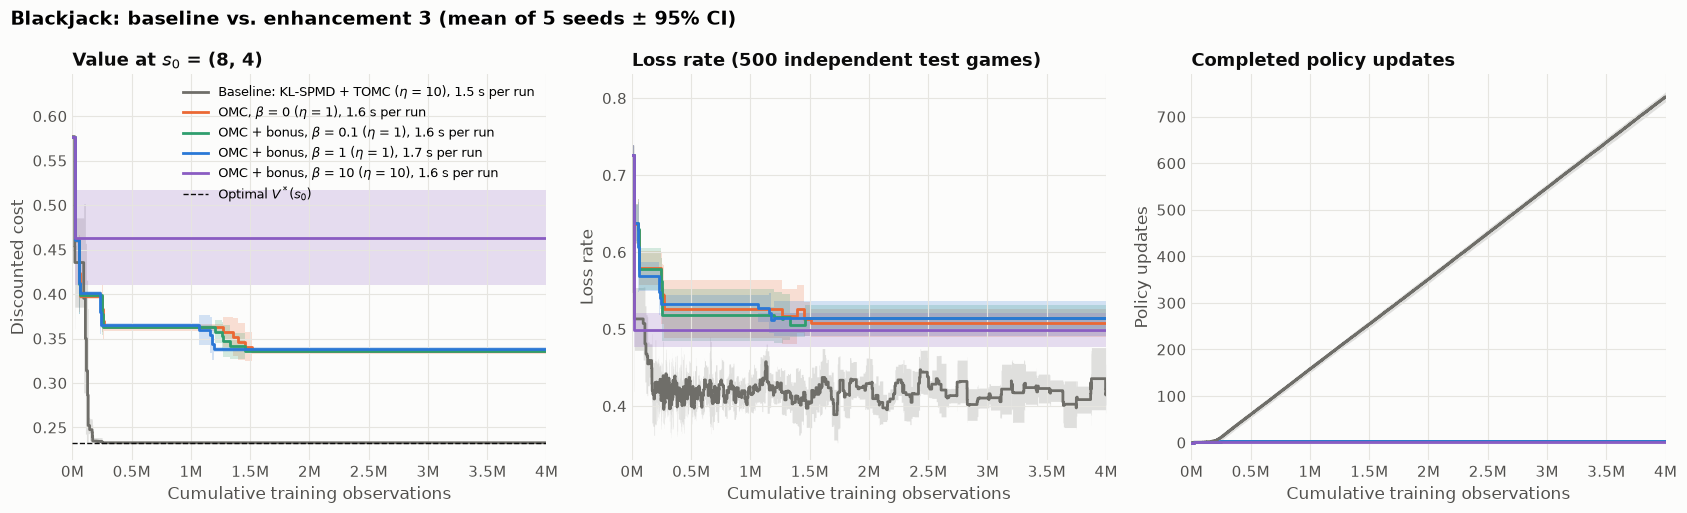

In [10]:
def apply_plot_style(large=False):
    plt.rcdefaults()
    plt.rcParams.update({
        "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "savefig.facecolor": BACKGROUND,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.spines.left": False, "axes.spines.bottom": False,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
        "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "legend.frameon": False, "font.family": "DejaVu Sans",
        "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10.5,
    })
    if large:
        plt.rcParams.update({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16,
                             "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14})


def plot_band(ax, points, curves, color, line_label, band_label=None, linewidth=2.0, lower=None):
    """Staircase mean across seeds with a shaded 95% confidence band.

    lower: a hard bound of the metric (V* for an exact value). The symmetric t-interval can
    cross it when seeds disagree (some converged, some not); the band is cut there.
    """
    mean, half_width = mean_ci(curves)
    low = mean - half_width if lower is None else np.maximum(mean - half_width, lower)
    ax.fill_between(points, low, mean + half_width, step="post",
                    color=color, alpha=0.2, linewidth=0, label=band_label)
    ax.step(points, mean, where="post", color=color, linewidth=linewidth, label=line_label)
    return mean, half_width


def save_figure(fig, name):
    FIGURES.mkdir(exist_ok=True)
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{suffix}", dpi=200, bbox_inches="tight")


def metric_curves(method_runs):
    """Aligned value, loss-rate and update curves for one method."""
    points = update_points(method_runs, SAMPLE_BUDGET)
    update_grid = update_points(method_runs, SAMPLE_BUDGET, key="update_samples")
    return {"points": points, "update_points": update_grid,
            "values": np.array([on_grid(run, points, "values")[:, REPORT_STATE] for run in method_runs]),
            "losses": np.array([on_grid(run, points, "loss_rate") for run in method_runs]),
            "updates": np.array([updates_on_grid(run, update_grid) for run in method_runs])}


millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
n_seeds = len(SEEDS)
def beta_name(beta):
    eta = CONFIGS[beta]["eta"]
    if beta == 0:
        return f"OMC, $\\beta$ = 0 ($\\eta$ = {eta:g})"
    return f"OMC + bonus, $\\beta$ = {beta:g} ($\\eta$ = {eta:g})"


METHODS = ([("baseline", f"Baseline: KL-SPMD + TOMC ($\\eta$ = {BASE_ETA:g})", baseline_runs, BASELINE_COLOR)]
           + [(beta, beta_name(beta), e3_runs[beta], BETA_COLORS[beta]) for beta in BETA_CANDIDATES])
curves = {key: metric_curves(method_runs) for key, _, method_runs, _ in METHODS}

# Each entry: (points, curves, color, legend label); value labels carry the training time.
value_series = [(curves[k]["points"], curves[k]["values"], color, f"{name}, {SECONDS[k]:.1f} s per run")
                for k, name, _, color in METHODS]
loss_series = [(curves[k]["points"], curves[k]["losses"], color, name) for k, name, _, color in METHODS]
update_series = [(curves[k]["update_points"], curves[k]["updates"], color, name)
                 for k, name, _, color in METHODS]
TITLE_START = "Blackjack: baseline vs. enhancement 3"

# Overview: three panels side by side, all methods in every panel.
apply_plot_style()
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, series, lower in zip(axes, (value_series, loss_series, update_series), (v_star, None, None)):
    for points, method_curves, color, label in series:
        plot_band(ax, points, method_curves, color, label, lower=lower)
axes[0].axhline(v_star, color=INK, linewidth=1, linestyle="--", label="Optimal $V^*(s_0)$")
axes[0].set(title=f"Value at $s_0$ = {REPORT_LABEL}", ylabel="Discounted cost")
axes[1].set(title=f"Loss rate ({TEST_GAMES} independent test games)", ylabel="Loss rate")
axes[2].set(title="Completed policy updates", ylabel="Policy updates")
axes[2].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes:
    ax.set(xlabel="Cumulative training observations", xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle(f"{TITLE_START} (mean of {n_seeds} seeds ± 95% CI)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh3_results")
plt.show()

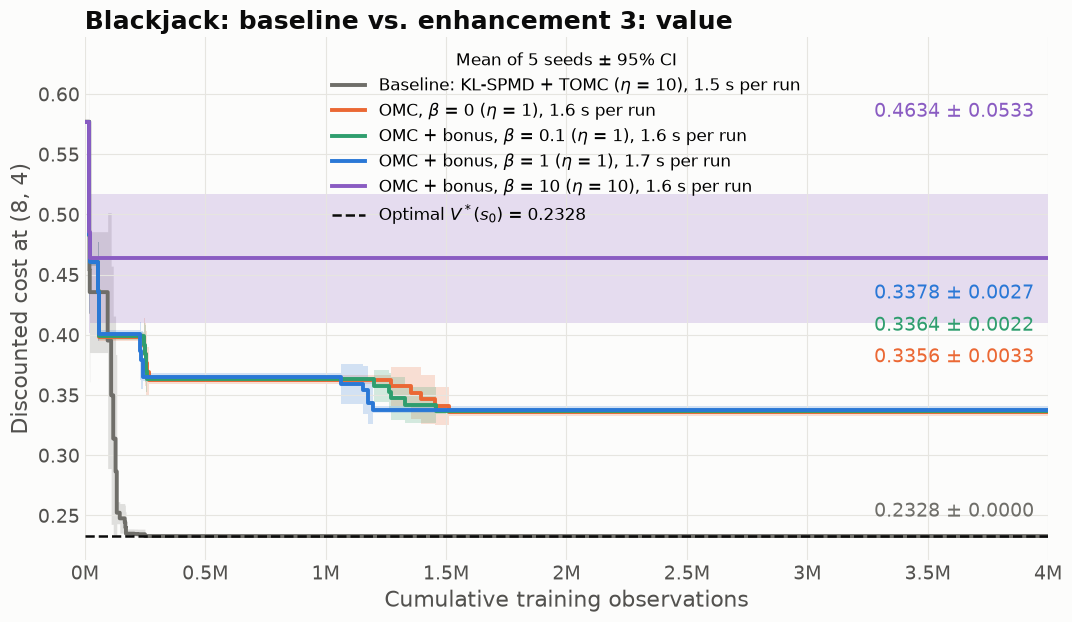

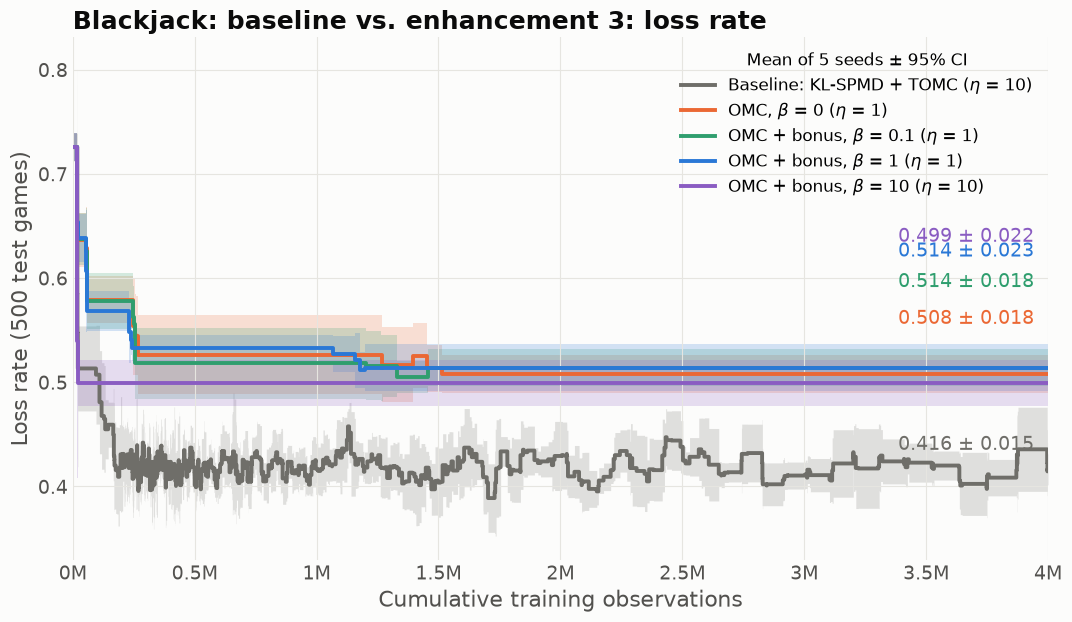

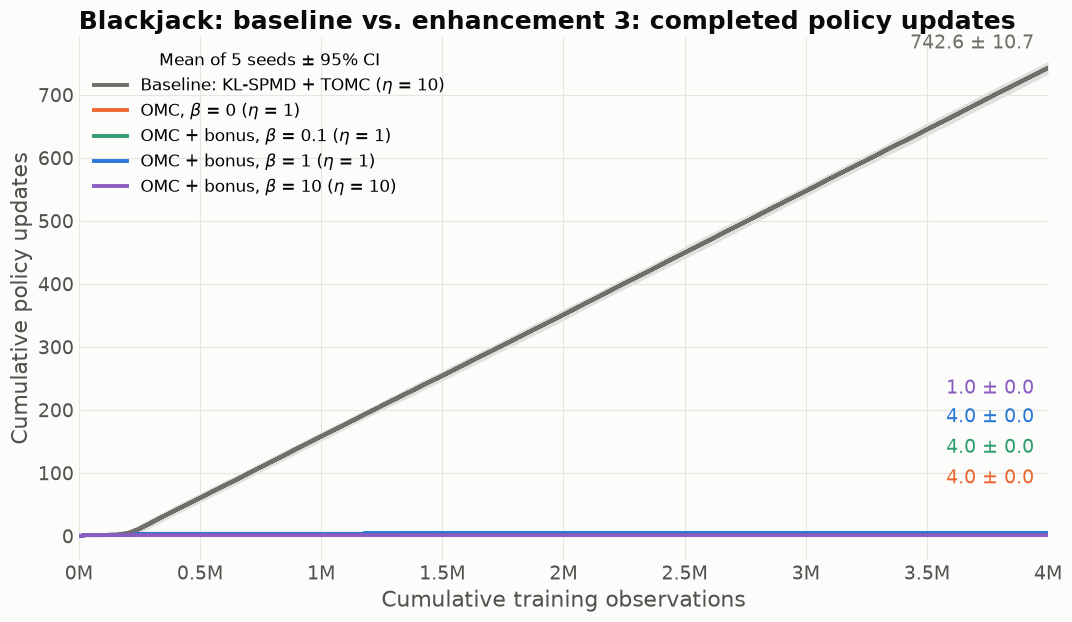

In [11]:
# Large slide figures, one per metric (same size and fonts as the other slide figures).
def slide_figure(series, title, ylabel, name, reference=None, reference_label=None,
                 value_format="{:.4f}", integer_axis=False, lower=None):
    """series: list of (points, curves, color, legend label), drawn with mean ± 95% CI."""
    apply_plot_style(large=True)
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for index, (points, method_curves, color, label) in enumerate(series):
        mean, half_width = plot_band(ax, points, method_curves, color, label, linewidth=2.8, lower=lower)
        # End labels are stacked so curves ending at the same height stay readable.
        ax.annotate(f"{value_format.format(mean[-1])} ± {value_format.format(half_width[-1])}",
                    (points[-1], mean[-1]), xytext=(-10, 14 + 22 * index), textcoords="offset points",
                    ha="right", color=color, fontsize=14)
    if reference is not None:
        ax.axhline(reference, color=INK, linewidth=1.8, linestyle="--", label=reference_label)
    ax.set(title=title, xlabel="Cumulative training observations", ylabel=ylabel,
           xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
    if integer_axis:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(loc="best", fontsize=12, title=f"Mean of {n_seeds} seeds ± 95% CI", title_fontsize=12)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()


slide_figure(value_series, f"{TITLE_START}: value", f"Discounted cost at {REPORT_LABEL}",
             "blackjack_enh3_value", reference=v_star,
             reference_label=f"Optimal $V^*(s_0)$ = {v_star:.4f}", lower=v_star)
slide_figure(loss_series, f"{TITLE_START}: loss rate", f"Loss rate ({TEST_GAMES} test games)",
             "blackjack_enh3_loss_rate", value_format="{:.3f}")
slide_figure(update_series, f"{TITLE_START}: completed policy updates", "Cumulative policy updates",
             "blackjack_enh3_updates", value_format="{:.1f}", integer_axis=True)

## 11. Tuning summary

Each cell is the exact gap at (8, 4) after 40,000 observations (log color scale, darker is
worse), with the number of completed updates. Rows: beta (0 is the OMC control). Each row's
selected eta is outlined in that beta's plot color.

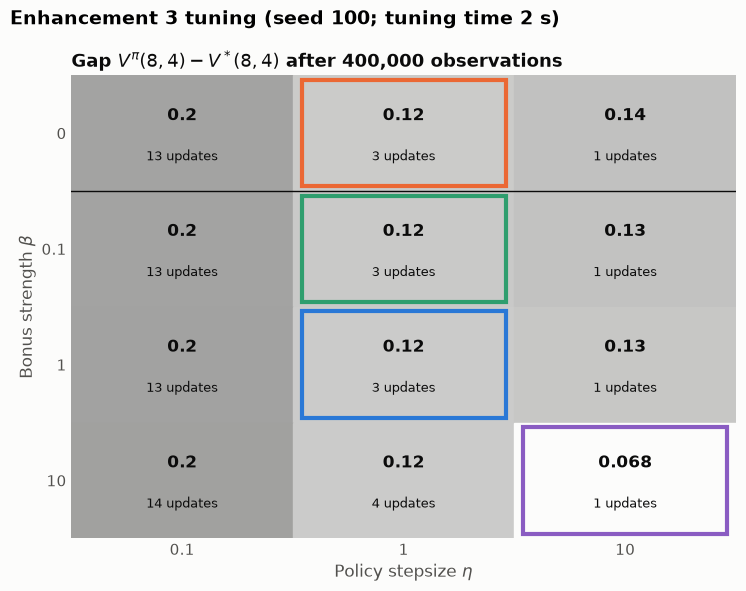

In [12]:
apply_plot_style()
fig, ax = plt.subplots(figsize=(7.5, 6.0))
cmap = LinearSegmentedColormap.from_list("gap", [BACKGROUND, "#3a3a38"])
floor = 1e-6
gaps = np.maximum(tuning["gap_at_reference"].to_numpy(), floor)
norm = LogNorm(vmin=gaps.min(), vmax=max(gaps.max(), 10 * gaps.min()))
winners = {(beta, config["eta"]): BETA_COLORS[beta] for beta, config in CONFIGS.items()}
for i, beta in enumerate(BETA_CANDIDATES):
    for j, eta in enumerate(ETA_CANDIDATES):
        row = tuning[(tuning["beta"] == beta) & (tuning["eta"] == eta)].iloc[0]
        gap = max(row["gap_at_reference"], floor)
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, color=cmap(norm(gap))))
        text_color = "white" if norm(gap) > 0.6 else INK
        ax.text(j, i - 0.15, f"{row['gap_at_reference']:.2g}", ha="center", va="center",
                fontsize=12, color=text_color, fontweight="bold")
        ax.text(j, i + 0.2, f"{int(row['policy_updates'])} updates", ha="center", va="center",
                fontsize=9, color=text_color)
        if (beta, eta) in winners:
            ax.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, fill=False,
                                   edgecolor=winners[(beta, eta)], linewidth=3))
ax.axhline(0.5, color=INK, linewidth=1)                       # Control row | bonus rows.
ax.set(xlim=(-0.5, len(ETA_CANDIDATES) - 0.5), ylim=(len(BETA_CANDIDATES) - 0.5, -0.5),
       xticks=range(len(ETA_CANDIDATES)), xticklabels=[f"{eta:g}" for eta in ETA_CANDIDATES],
       yticks=range(len(BETA_CANDIDATES)), yticklabels=[f"{beta:g}" for beta in BETA_CANDIDATES],
       xlabel="Policy stepsize $\\eta$", ylabel="Bonus strength $\\beta$",
       title=f"Gap $V^{{\\pi}}{REPORT_LABEL} - V^*{REPORT_LABEL}$ after {TUNING_BUDGET:,} observations")
ax.grid(False)
fig.suptitle(f"Enhancement 3 tuning (seed {TUNING_SEED}; tuning time {tuning_seconds:.0f} s)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh3_tuning")
plt.show()

## 12. Comparison table at the full budget

In [13]:
comparison_rows = []
for key, name, method_runs, _ in METHODS:
    metrics = pd.DataFrame([final_metrics(run) for run in method_runs])
    comparison_rows.append({
        "method": name.replace("$\\eta$", "eta").replace("$\\beta$", "beta"),
        "gap_at_reference": format_mean_ci(metrics["gap_at_reference"]),
        "mean_gap_all_states": format_mean_ci(metrics["mean_gap_all_states"]),
        "loss_rate": format_mean_ci(metrics["loss_rate"], 3),
        "policy_updates": format_mean_ci(metrics["policy_updates"], 1),
        "seconds_per_run": format_mean_ci(metrics["train_seconds"], 1)})
print(f"All methods at {SAMPLE_BUDGET:,} training observations (mean ± 95% CI over {n_seeds} seeds):")
print(pd.DataFrame(comparison_rows).to_string(index=False))
print(f"Tuning time, reported separately: E3 ({len(tuning)} configurations) {tuning_seconds:.1f} s; "
      f"baseline ({len(ETA_CANDIDATES)} stepsizes) {baseline_tuning_seconds:.1f} s.")

All methods at 4,000,000 training observations (mean ± 95% CI over 5 seeds):
                             method gap_at_reference mean_gap_all_states     loss_rate policy_updates seconds_per_run
Baseline: KL-SPMD + TOMC (eta = 10)  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.416 ± 0.015   742.6 ± 10.7       1.5 ± 0.1
            OMC, beta = 0 (eta = 1)  0.1028 ± 0.0033     0.0924 ± 0.0023 0.508 ± 0.018      4.0 ± 0.0       1.6 ± 0.0
  OMC + bonus, beta = 0.1 (eta = 1)  0.1036 ± 0.0022     0.0928 ± 0.0024 0.514 ± 0.018      4.0 ± 0.0       1.6 ± 0.1
    OMC + bonus, beta = 1 (eta = 1)  0.1050 ± 0.0027     0.0951 ± 0.0031 0.514 ± 0.023      4.0 ± 0.0       1.7 ± 0.1
  OMC + bonus, beta = 10 (eta = 10)  0.2306 ± 0.0533     0.1015 ± 0.0154 0.499 ± 0.022      1.0 ± 0.0       1.6 ± 0.0
Tuning time, reported separately: E3 (12 configurations) 2.1 s; baseline (3 stepsizes) 0.5 s.


## 13. Learned policy of the first seed

P(HIT) of the final policy of the beta with the smallest mean gap at (8, 4), next to the
optimal action.

In [14]:
best_beta = min(BETA_CANDIDATES, key=lambda b: np.mean([final_metrics(r)["gap_at_reference"]
                                                        for r in e3_runs[b]]))
final = e3_runs[best_beta][0]["final_policy"]
policy_table = pd.DataFrame(
    [[f"{final[state2ID(p, d), HIT]:.2f} ({'SH'[OPTIMAL_ACTIONS[state2ID(p, d)]]})"
      for d in DEALER_CARDS] for p in PLAYER_SUMS],
    index=[f"sum {p}" for p in PLAYER_SUMS], columns=[f"dealer {d}" for d in DEALER_CARDS])
print(f"Seed {SEEDS[0]}: final P(HIT) for beta = {best_beta:g}, optimal action in brackets")
print(policy_table.to_string())

Seed 0: final P(HIT) for beta = 0, optimal action in brackets
        dealer 2  dealer 3  dealer 4  dealer 5
sum 4   0.74 (H)  0.66 (H)  0.72 (H)  0.71 (H)
sum 5   0.78 (H)  0.66 (H)  0.77 (H)  0.80 (H)
sum 6   0.88 (H)  0.80 (H)  0.89 (H)  0.90 (H)
sum 7   0.80 (H)  0.72 (H)  0.82 (H)  0.84 (H)
sum 8   0.72 (H)  0.56 (H)  0.69 (H)  0.71 (H)
sum 9   0.21 (S)  0.18 (S)  0.14 (S)  0.23 (S)
sum 10  0.01 (S)  0.01 (S)  0.00 (S)  0.00 (S)
sum 11  0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
